## BÀI 4 NÂNG CAO: ACF/PACF → XÁC ĐỊNH (p, q, P, Q) CHO SARIMA

**Dataset 2:** AirPassengers, số hành khách hàng không theo tháng, 144 quan sát (01/1949 – 12/1960), chu kỳ mùa vụ **s = 12**.

**Bước 4 của đề nâng cao:** ACF/PACF → xác định (p, q, P, Q). Tham số đề gợi ý: **s = 12, d = 1, D = 1**.

**Cách đọc notebook này**
- Mục **TRẢ LỜI** = chỗ trả lời yêu cầu của đề.
- **Tự hỏi:**  câu tự hỏi khi làm đến đâu hiểu đến đó.
- **Đổi số:**  ví dụ đổi số xem chuyện gì xảy ra.

### 0. Thư viện và các hàm dùng chung

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["figure.dpi"] = 100

URL_AIR = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"


def doc_air():
    """Ưu tiên đọc file trong repo (data/raw/airline-passengers.csv); không có thì tải từ URL.
    Thử cả 2 vị trí để notebook chạy được dù đặt ở thư mục BT_Nangcao hay BT_Nangcao/src."""
    for p in [Path("data/raw/airline-passengers.csv"), Path("../data/raw/airline-passengers.csv")]:
        if p.is_file():
            print("Đọc dữ liệu từ file cục bộ:", p)
            return pd.read_csv(p)
    print("Không thấy file cục bộ, đọc từ URL:", URL_AIR)
    return pd.read_csv(URL_AIR)

def kiem_dinh_adf(chuoi, ten):
    """Chạy ADF. H0: chuỗi có nghiệm đơn vị (KHÔNG dừng). p <= 0.05 => bác bỏ H0 => DỪNG."""
    r = adfuller(chuoi.dropna(), regression="c", autolag="AIC")
    dung = r[1] <= 0.05
    print(f"[{ten}]  ADF = {r[0]:.4f} | p-value = {r[1]:.4f} | số lag = {r[2]}  =>  {'DỪNG' if dung else 'KHÔNG DỪNG'}")
    return r[1]


def lag_vuot_nguong(gia_tri, n, toi_da):
    """Trả về các lag (1..toi_da) có |hệ số| vượt ngưỡng tin cậy 95% = 1.96 / sqrt(n).
    Lưu ý: gia_tri[0] là lag 0 (luôn = 1) nên vòng lặp bắt đầu từ lag 1."""
    nguong = 1.96 / np.sqrt(n)
    return [k for k in range(1, toi_da + 1) if abs(gia_tri[k]) > nguong]


def ve_acf_pacf(x, tieu_de, lags=36):
    """Vẽ ACF và PACF cạnh nhau. Vùng xanh = khoảng tin cậy 95%; đường đỏ chấm = lag 12, 24, 36 (mùa vụ)."""
    fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
    plot_acf(x, lags=lags, ax=ax[0])
    ax[0].set_title(f"ACF - {tieu_de}")
    plot_pacf(x, lags=lags, ax=ax[1], method="ywm")
    ax[1].set_title(f"PACF - {tieu_de}")
    for a in ax:
        for k in (12, 24, 36):
            a.axvline(k, color="red", linestyle=":", alpha=0.5)
        a.set_xlabel("Lag (tháng)")
    plt.tight_layout()
    plt.show()


def tom_tat_acf_pacf(x, ten, lags=36):
    """In các lag vượt ngưỡng và giá trị tại các lag quan trọng. Trả về (acf, pacf, n)."""
    x = x.dropna()
    n = len(x)
    a = acf(x, nlags=lags)
    p = pacf(x, nlags=lags, method="ywm")
    print(f"[{ten}]  n = {n} | ngưỡng tin cậy 95% = ±{1.96 / np.sqrt(n):.3f}")
    print("  Lag ACF  vượt ngưỡng:", lag_vuot_nguong(a, n, lags))
    print("  Lag PACF vượt ngưỡng:", lag_vuot_nguong(p, n, lags))
    bang = pd.DataFrame({"ACF": a, "PACF": p}).round(2)
    bang.index.name = "Lag"
    display(bang.loc[[1, 2, 3, 4, 5, 11, 12, 13, 24, 36]].T)
    return a, p, n


def theta_tu_rho1(rho1):
    """Ước lượng thô hệ số MA(1) từ ACF lag 1, dùng công thức rho1 = theta / (1 + theta^2).
    Giải ra: theta = (1 - sqrt(1 - 4*rho1^2)) / (2*rho1). Chỉ có nghiệm khi |rho1| < 0.5."""
    if abs(rho1) >= 0.5:
        return None
    return (1 - np.sqrt(1 - 4 * rho1 ** 2)) / (2 * rho1)

### 1. Đọc dữ liệu, đặt `Month` làm index thời gian

**Tự hỏi — Vì sao phải đổi `Month` thành index thời gian?** Để `diff(12)` hiểu "12 quan sát trước" là cùng tháng năm trước, và để mô hình biết chu kỳ s = 12.
`asfreq("MS")` gán tần suất đầu tháng và chèn NaN nếu thiếu tháng (ở đây không thiếu).

In [2]:
df = doc_air()
df["Month"] = pd.to_datetime(df["Month"])
y = df.set_index("Month")["Passengers"].sort_index().asfreq("MS")

print("Số quan sát:", len(y), "| từ", y.index.min().date(), "đến", y.index.max().date(), "| thiếu:", y.isna().sum())
y.head()

Đọc dữ liệu từ file cục bộ: data/raw/airline-passengers.csv
Số quan sát: 144 | từ 1949-01-01 đến 1960-12-01 | thiếu: 0


Month
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: Passengers, dtype: int64

### 2. Chuẩn bị chuỗi: log, rồi sai phân thường (d = 1) và sai phân mùa vụ (D = 1)

**Tự hỏi — Vì sao dùng log?** Bài 1 nâng cao đã nhận xét biên độ mùa vụ **tăng dần theo mức của chuỗi** (dạng nhân). Log biến nhân thành cộng,
giúp biên độ mùa vụ ổn định. Thứ tự: **log trước, sai phân sau**.

**Tự hỏi — Vì sao cần cả d = 1 và D = 1?** d = 1 (so với tháng trước) loại **xu hướng**. D = 1 với s = 12 (so với cùng tháng năm trước) loại **mùa vụ**.
Mất 1 + 12 = 13 quan sát đầu, nên 144 − 13 = 131 quan sát.

In [3]:
ly = np.log(y)                           # chuỗi log
ly_d1 = ly.diff().dropna()               # chỉ d = 1
ly_d1_D1 = ly.diff().diff(12).dropna()   # d = 1 và D = 1 (s = 12)  <-- chuỗi dùng cho ACF/PACF

print("Số quan sát sau d=1 và D=1:", len(ly_d1_D1), "(= 144 - 1 - 12)")
kiem_dinh_adf(y, "Chuỗi gốc")
kiem_dinh_adf(y.diff(), "Gốc + d=1")
kiem_dinh_adf(y.diff().diff(12), "Gốc + d=1 + D=1 (không log)")
_ = kiem_dinh_adf(ly_d1_D1, "Log + d=1 + D=1")

Số quan sát sau d=1 và D=1: 131 (= 144 - 1 - 12)
[Chuỗi gốc]  ADF = 0.8154 | p-value = 0.9919 | số lag = 13  =>  KHÔNG DỪNG
[Gốc + d=1]  ADF = -2.8293 | p-value = 0.0542 | số lag = 12  =>  KHÔNG DỪNG
[Gốc + d=1 + D=1 (không log)]  ADF = -15.5956 | p-value = 0.0000 | số lag = 0  =>  DỪNG
[Log + d=1 + D=1]  ADF = -4.4433 | p-value = 0.0002 | số lag = 12  =>  DỪNG


**Nhận xét:** chuỗi gốc **không dừng** (p = 0.9919), chỉ d = 1 vẫn chưa dừng (p = 0.0542, sát ngưỡng). Sau khi áp dụng cả d = 1 và D = 1 (có hoặc không log), chuỗi **dừng**
(log: p = 0.0002), nên có thể vẽ ACF/PACF.

### 3. ACF/PACF của chuỗi log + d = 1 + D = 1, rồi đọc (p, q) và (P, Q)

**Cách đọc theo hai nhóm lag:**
- **Lag 1 đến 11** (phần không mùa vụ) → gợi ý **p, q**.
- **Lag 12, 24, 36** (bội của s) → gợi ý **P, Q**.

Ví dụ số: Ngưỡng tin cậy phụ thuộc n: với n = 131 thì ±1.96/√131 = ±0.171. Cột nào vượt ngưỡng mới xem là có ý nghĩa.

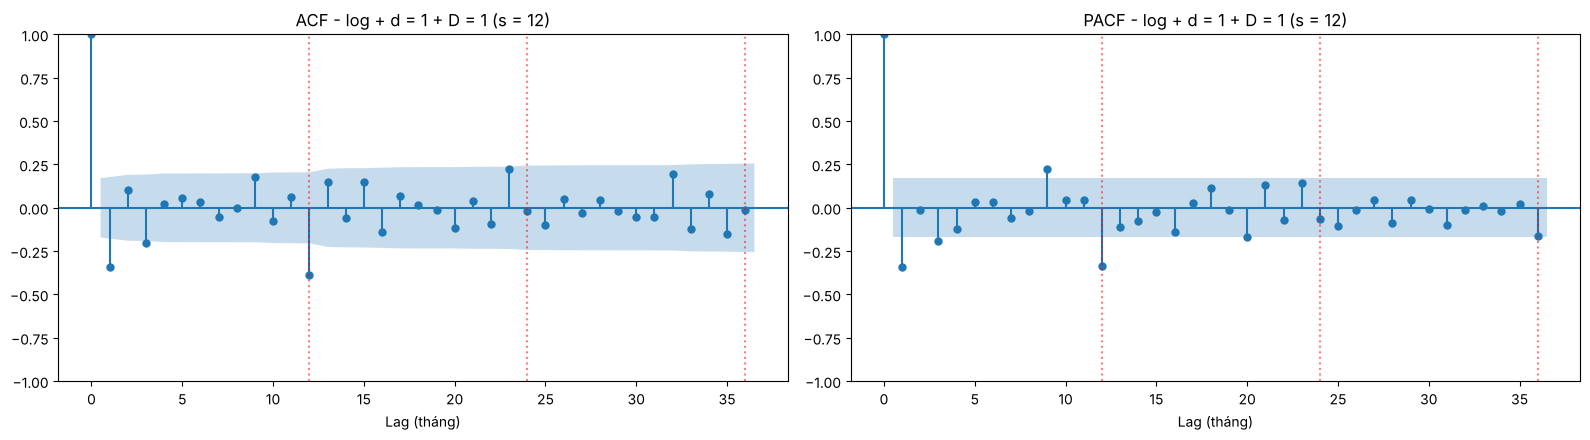

[AirPassengers log + d=1 + D=1]  n = 131 | ngưỡng tin cậy 95% = ±0.171
  Lag ACF  vượt ngưỡng: [1, 3, 9, 12, 23, 32]
  Lag PACF vượt ngưỡng: [1, 3, 9, 12]


Lag,1,2,3,4,5,11,12,13,24,36
ACF,-0.34,0.11,-0.20,0.02,0.06,0.06,-0.39,0.15,-0.02,-0.01
PACF,-0.34,-0.01,-0.19,-0.13,0.03,0.05,-0.34,-0.11,-0.07,-0.16


In [4]:
ve_acf_pacf(ly_d1_D1, "log + d = 1 + D = 1 (s = 12)")
a_log, p_log, n_log = tom_tat_acf_pacf(ly_d1_D1, "AirPassengers log + d=1 + D=1")

**Đọc biểu đồ (n = 131, ngưỡng ±0.171):**
- **Phần không mùa vụ (lag 1 đến 11):** ACF lag 1 = −0.34 vượt ngưỡng, lag 2 = 0.11 trong vùng xanh. Lag 3 (ACF −0.20, PACF −0.19) chỉ vượt nhẹ, có thể là ngẫu nhiên.
  PACF lag 1 = −0.34, lag 2 ≈ −0.01. Cả ACF lẫn PACF đều chỉ có lag 1 nổi bật, nên cũng **mơ hồ giữa MA(1) và AR(1)**.
- **Phần mùa vụ:** ACF lag **12 = −0.39 vượt ngưỡng**, lag 24 = −0.02 và lag 36 = −0.01 nằm trong vùng xanh → **ACF cắt cụt sau lag 12**.
  PACF lag 12 = −0.34 cũng vượt ngưỡng, còn lag 24 = −0.07 và lag 36 = −0.16 nằm trong vùng xanh.
  Như vậy ở các lag mùa vụ, **cả ACF và PACF đều chỉ có một đỉnh ở lag 12**, nên về lý thuyết **mơ hồ giữa MA mùa vụ (Q = 1) và AR mùa vụ (P = 1)**.
- Một vài lag lẻ (ACF lag 9, 23, 32; PACF lag 9) vượt nhẹ. Với 36 lag và mức 95%, kỳ vọng khoảng 1 đến 2 lag vượt ngưỡng chỉ do ngẫu nhiên, nên không diễn giải các lag lẻ này.

### 4. Đổi số: nếu bỏ D = 1, hoặc bỏ log, thì ACF/PACF thay đổi thế nào?

Đây là cách **chỉ ra vì sao** cần D = 1 và cần log.

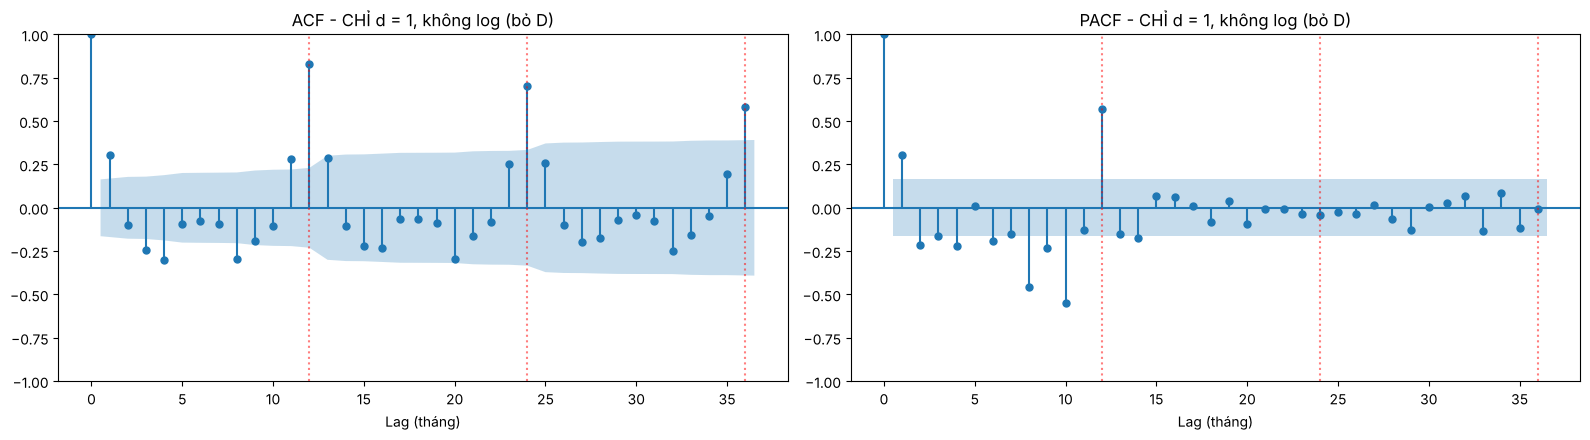

[Gốc + d=1 (bỏ D)]  n = 143 | ngưỡng tin cậy 95% = ±0.164
  Lag ACF  vượt ngưỡng: [1, 3, 4, 8, 9, 11, 12, 13, 15, 16, 20, 23, 24, 25, 27, 28, 32, 35, 36]
  Lag PACF vượt ngưỡng: [1, 2, 4, 6, 8, 9, 10, 12, 14]


Lag,1,2,3,4,5,11,12,13,24,36
ACF,0.3,-0.10,-0.24,-0.30,-0.09,0.28,0.83,0.28,0.70,0.58
PACF,0.3,-0.21,-0.16,-0.22,0.01,-0.13,0.57,-0.15,-0.04,-0.01


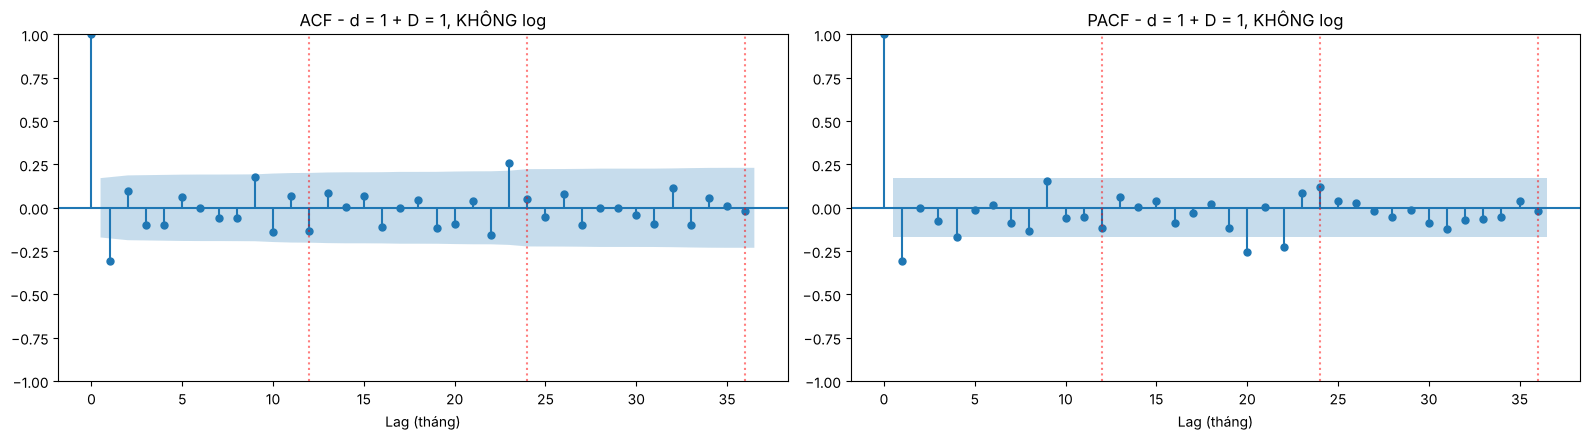

[Gốc + d=1 + D=1 (không log)]  n = 131 | ngưỡng tin cậy 95% = ±0.171
  Lag ACF  vượt ngưỡng: [1, 9, 23]
  Lag PACF vượt ngưỡng: [1, 20, 22]


Lag,1,2,3,4,5,11,12,13,24,36
ACF,-0.31,0.1,-0.10,-0.10,0.06,0.07,-0.13,0.09,0.05,-0.02
PACF,-0.31,-0.0,-0.07,-0.17,-0.02,-0.05,-0.12,0.06,0.12,-0.02


In [5]:
y_d1_chi = y.diff().dropna()                 # chỉ d = 1, không log
y_d1_D1_khong_log = y.diff().diff(12).dropna()  # d = 1 và D = 1, không log

ve_acf_pacf(y_d1_chi, "CHỈ d = 1, không log (bỏ D)")
a_d, p_d, n_d = tom_tat_acf_pacf(y_d1_chi, "Gốc + d=1 (bỏ D)")

ve_acf_pacf(y_d1_D1_khong_log, "d = 1 + D = 1, KHÔNG log")
a_r, p_r, n_r = tom_tat_acf_pacf(y_d1_D1_khong_log, "Gốc + d=1 + D=1 (không log)")

In [6]:
def dong(a, p, n):
    return {"n": n, "ACF lag 1": a[1], "ACF lag 12": a[12], "ACF lag 24": a[24],
            "PACF lag 12": p[12], "PACF lag 24": p[24]}

bang_ss = pd.DataFrame({
    "d=1 (bỏ D), không log": dong(a_d, p_d, n_d),
    "d=1 + D=1, không log": dong(a_r, p_r, n_r),
    "d=1 + D=1, có log": dong(a_log, p_log, n_log),
}).T
bang_ss["n"] = bang_ss["n"].astype(int)          # n là số đếm nên để dạng số nguyên
display(bang_ss.round(2))

,n,ACF lag 1,ACF lag 12,ACF lag 24,PACF lag 12,PACF lag 24
"d=1 (bỏ D), không log",143,0.30,0.83,0.70,0.57,-0.04
"d=1 + D=1, không log",131,-0.31,-0.13,0.05,-0.12,0.12
"d=1 + D=1, có log",131,-0.34,-0.39,-0.02,-0.34,-0.07


**Nhận xét:**
- **Bỏ D:** ACF lag 12 = 0.83, lag 24 = 0.70, lag 36 = 0.58 → mùa vụ còn nguyên, nên **bắt buộc có D = 1**.
- **Có D nhưng không log:** ACF lag 12 = −0.13 (và PACF lag 12 = −0.12) đều **nằm trong vùng xanh**, nên phần mùa vụ trở nên **mơ hồ**, khó quyết định Q.
- **Có cả D và log:** ACF lag 12 = −0.39 vượt ngưỡng rõ ràng, nên chọn được Q. Đây là lý do nên **log trước** (biên độ mùa vụ của AirPassengers tăng theo thời gian).

### 5. Từ ACF ước lượng thô hệ số MA

Với MA(1): ACF(1) = θ / (1 + θ²), giải ngược ra θ. Với phần mùa vụ MA(1) ở lag 12 cũng dùng công thức tương tự (Θ).
Cách này chỉ cho biết **độ lớn gần đúng** của hệ số để kiểm tra đề xuất hợp lý; giá trị chính xác sẽ do bước fit SARIMA tìm ra.

In [7]:
th = theta_tu_rho1(a_log[1])
TH = theta_tu_rho1(a_log[12])
print(f"ACF(1)  = {a_log[1]:.2f}  ->  theta ≈ {th:.2f}   (hệ số MA không mùa vụ)")
print(f"ACF(12) = {a_log[12]:.2f}  ->  Theta ≈ {TH:.2f}   (hệ số MA mùa vụ, ước lượng thô)")

ACF(1)  = -0.34  ->  theta ≈ -0.39   (hệ số MA không mùa vụ)
ACF(12) = -0.39  ->  Theta ≈ -0.47   (hệ số MA mùa vụ, ước lượng thô)


Hai hệ số đều âm và có độ lớn vừa phải (khoảng −0.4 đến −0.5), hợp lý với một mô hình MA ở cả hai phần.

### 6. Bảng quy tắc nhận dạng

| Phần | Dấu hiệu | Kết luận |
|---|---|---|
| Không mùa vụ (lag 1 đến 11) | ACF cắt sau lag q, PACF giảm dần | MA(q) |
| Không mùa vụ (lag 1 đến 11) | PACF cắt sau lag p, ACF giảm dần | AR(p) |
| Mùa vụ (lag 12, 24, 36) | ACF cắt sau lag 12, PACF giảm dần ở các lag mùa vụ | MA mùa vụ, Q = 1 |
| Mùa vụ (lag 12, 24, 36) | PACF cắt sau lag 12, ACF giảm dần ở các lag mùa vụ | AR mùa vụ, P = 1 |

## KẾT QUẢ: XÁC ĐỊNH (p, q, P, Q)

**Chuỗi dùng:** log + d = 1 + D = 1, s = 12 (ADF p = 0.0002, n = 131).

| Tham số | Giá trị | Căn cứ |
|---|---|---|
| **d** | 1 | loại xu hướng (gợi ý của đề) |
| **D** | 1 (s = 12) | loại mùa vụ (gợi ý của đề); bỏ D thì ACF lag 12 = 0.83 |
| **q** | 1 | ACF lag 1 = −0.34 vượt ngưỡng, lag 2 (0.11) trong vùng xanh |
| **p** | 0 | PACF cũng chỉ có lag 1 vượt ngưỡng (lag 2 = −0.01), nên về lý thuyết mơ hồ giữa MA(1) và AR(1); chọn MA(1) cho khớp "airline model", AR(1) giữ làm ứng viên đối chiếu |
| **Q** | 1 | ACF lag 12 = −0.39 vượt ngưỡng, rồi tắt hẳn (lag 24 = −0.02, lag 36 = −0.01) |
| **P** | 0 | PACF lag 24 (−0.07) và 36 (−0.16) nằm trong vùng xanh; tuy nhiên PACF lag 12 = −0.34 cũng vượt ngưỡng nên P = 1 vẫn có thể |

**Mô hình đề xuất chính: SARIMA(0,1,1)(0,1,1)₁₂** (thường gọi là "airline model").

**Ứng viên đối chiếu (để Bài 5 nâng cao so sánh AIC/BIC và sai số trên tập test):**
- SARIMA(1,1,0)(0,1,1)₁₂ (thay MA(1) bằng AR(1), vì PACF cũng chỉ có đỉnh ở lag 1)
- SARIMA(1,1,1)(0,1,1)₁₂ (có cả AR(1) và MA(1))
- SARIMA(0,1,1)(1,1,0)₁₂ (thay MA mùa vụ bằng AR mùa vụ, vì PACF lag 12 cũng vượt ngưỡng)

**Lưu ý trung thực:**
- Với **chuỗi không log**, lag 12 nằm trong vùng xanh (ACF −0.13), nên phần mùa vụ mơ hồ. Nhóm cần **thống nhất một cách** (log hoặc không) giữa Bài 3 nâng cao và các bài sau.
- ACF/PACF chỉ **gợi ý** bậc mô hình, đọc có phần chủ quan. Mô hình cuối cùng do AIC/BIC và phần dư (residual) quyết định ở bước fit SARIMA.

**Nếu thầy cô hỏi vặn:**
- *Vì sao P = 0 mà Q = 1?* Cả ACF và PACF đều có một đỉnh ở lag 12 nên đọc biểu đồ đơn thuần là mơ hồ giữa P = 1 và Q = 1. Chọn Q = 1 vì ACF tắt sạch ngay sau lag 12 (lag 24 = −0.02, lag 36 = −0.01), trong khi PACF lag 36 = −0.16 chưa tắt hẳn; thêm nữa "airline model" là mô hình kinh điển cho dạng dữ liệu này. Phương án P = 1 được giữ làm ứng viên đối chiếu, AIC/BIC sẽ quyết định.
- *Vì sao phải D = 1?* Bỏ D thì ACF lag 12, 24, 36 = 0.83, 0.70, 0.58: mùa vụ còn nguyên.
- *Vì sao phải log?* Biên độ mùa vụ tăng theo mức chuỗi; không log thì đỉnh lag 12 mờ đi (−0.13) và khó xác định Q.

In [ ]:
p, d, q = 0, 1, 1
P, D, Q = 0, 1, 1